In [17]:
# !pip install matplotlib pandas mlxtend

In [ ]:
import json


def load_classes_from_notebook(ipynb_path):
    """Extracts and executes class/import definitions from an .ipynb file without running its main benchmark."""
    with open(ipynb_path, "r", encoding="utf-8") as f:
        nb = json.load(f)

    namespace = {}
    for cell in nb["cells"]:
        if cell["cell_type"] == "code":
            source = "".join(cell["source"])
            # Skip any cell that runs the main benchmark loop
            if 'if __name__ == "__main__":' in source or "if __name__ == '__main__':" in source:
                continue
            # Also skip standalone calls to run_benchmark(...) if not wrapped in __main__
            if "run_benchmark(" in source and "def run_benchmark" not in source:
                continue
            exec(source, namespace)

    return namespace


apriori = load_classes_from_notebook("Apriori_Algorithm.ipynb")
fpgrowth = load_classes_from_notebook("FP_Growth.ipynb")

# Grab the classes from each notebook's namespace
AprioriTrie = apriori["AprioriTrie"]
FPGrowth = fpgrowth["FPGrowth"]

print("Loaded classes successfully:", AprioriTrie, FPGrowth)

Loaded classes successfully: <class 'AprioriTrie'> <class 'FPGrowth'>


In [ ]:
import os
import time
import tracemalloc
import matplotlib.pyplot as plt
import pandas as pd

def run_comparison_benchmark(dataset_name, filepath, thresholds):
    """Runs AprioriTrie and FPGrowth on identical thresholds and logs Time & Peak RAM."""
    if not os.path.exists(filepath):
        print(f"[SKIPPED] File not found: {filepath}")
        return pd.DataFrame()

    records = []
    print(f"\n{'=' * 75}")
    print(f"Benchmarking: {dataset_name} ({filepath})")
    print(f"{'=' * 75}")

    for sup in thresholds:
        # Run AprioriTrie (uses min_support_ratio)
        tracemalloc.start()
        t0 = time.perf_counter()
        ap_model = AprioriTrie(min_support_ratio=sup)
        ap_freq, total_tx, min_cnt = ap_model.fit(filepath)
        ap_time = time.perf_counter() - t0
        _, ap_peak = tracemalloc.get_traced_memory()
        tracemalloc.stop()

        # Run FPGrowth (uses min_support)
        tracemalloc.start()
        t0 = time.perf_counter()
        fp_model = FPGrowth(min_support=sup)
        fp_freq, _, _ = fp_model.fit(filepath)
        fp_time = time.perf_counter() - t0
        _, fp_peak = tracemalloc.get_traced_memory()
        tracemalloc.stop()

        # Verify both algorithms find the exact same frequent itemset count
        assert ap_freq == fp_freq, f"Mismatch at {sup}: Apriori={ap_freq}, FP={fp_freq}"
        
        ap_mb = ap_peak / (1024 * 1024)
        fp_mb = fp_peak / (1024 * 1024)

        records.append({
            "Dataset": dataset_name,
            "Support_%": sup * 100,
            "Min_Count": min_cnt,
            "Frequent_Sets": fp_freq,
            "Apriori_Time_s": ap_time,
            "FPGrowth_Time_s": fp_time,
            "Apriori_RAM_MB": ap_mb,
            "FPGrowth_RAM_MB": fp_mb,
        })
        print(
            f"Sup: {sup * 100:>5.2f}% (MinCnt={min_cnt:<6,}) | Sets: {fp_freq:<8,} | "
            f"Time: Apriori={ap_time:.3f}s, FP={fp_time:.3f}s | "
            f"RAM: Apriori={ap_mb:.2f}MB, FP={fp_mb:.2f}MB"
        )

    return pd.DataFrame(records)



In [ ]:

def plot_comparisons(results_dict):
    valid = {k: v for k, v in results_dict.items() if not v.empty}
    if not valid:
        print("No data available to plot.")
        return

    fig, axes = plt.subplots(len(valid), 2, figsize=(14, 4.5 * len(valid)), squeeze=False)
    fig.suptitle(
        "Trie-Apriori vs. FP-Growth: Execution Time & Peak Memory Comparison",
        fontsize=15,
        fontweight="bold",
        y=1.01,
    )

    for idx, (name, df) in enumerate(valid.items()):
        x = df["Support_%"]

        # Left Chart: Execution Time vs. Minimum Support
        ax_time = axes[idx, 0]
        ax_time.plot(x, df["Apriori_Time_s"], marker="o", linewidth=2, color="#d9534f", label="Trie-Apriori")
        ax_time.plot(x, df["FPGrowth_Time_s"], marker="s", linewidth=2, color="#0275d8", label="FP-Growth")
        ax_time.set_title(f"{name} — Execution Time", fontsize=12, fontweight="bold")
        ax_time.set_xlabel("Minimum Support (%)")
        ax_time.set_ylabel("Time (Seconds)")
        ax_time.grid(True, linestyle="--", alpha=0.6)
        ax_time.legend()

        # Right Chart: Peak Memory vs. Minimum Support
        ax_mem = axes[idx, 1]
        ax_mem.plot(x, df["Apriori_RAM_MB"], marker="o", linestyle="--", linewidth=2, color="#d9534f", label="Trie-Apriori")
        ax_mem.plot(x, df["FPGrowth_RAM_MB"], marker="s", linestyle="--", linewidth=2, color="#0275d8", label="FP-Growth")
        ax_mem.set_title(f"{name} — Peak Memory Usage", fontsize=12, fontweight="bold")
        ax_mem.set_xlabel("Minimum Support (%)")
        ax_mem.set_ylabel("Peak RAM (MB)")
        ax_mem.grid(True, linestyle="--", alpha=0.6)
        ax_mem.legend()

    plt.tight_layout()
    plt.savefig("apriori_vs_fpgrowth_comparison.png", dpi=300, bbox_inches="tight")
    plt.show()


Benchmarking: Chess --> Dense Dataset (chess.dat.gz)
Sup: 70.00% (MinCnt=2,238 ) | Sets: 48,731   | Time: Apriori=257.827s, FP=1.079s | RAM: Apriori=12.86MB, FP=9.97MB
Sup: 75.00% (MinCnt=2,397 ) | Sets: 20,993   | Time: Apriori=105.553s, FP=0.584s | RAM: Apriori=5.71MB, FP=9.53MB
Sup: 80.00% (MinCnt=2,557 ) | Sets: 8,227    | Time: Apriori=40.119s, FP=0.334s | RAM: Apriori=2.49MB, FP=3.97MB
Sup: 85.00% (MinCnt=2,717 ) | Sets: 2,669    | Time: Apriori=10.972s, FP=0.222s | RAM: Apriori=1.07MB, FP=1.40MB
Sup: 90.00% (MinCnt=2,877 ) | Sets: 622      | Time: Apriori=2.857s, FP=0.175s | RAM: Apriori=0.55MB, FP=0.40MB

Benchmarking: Mushroom --> Dense Dataset (mushroom.dat.gz)
Sup: 35.00% (MinCnt=2,844 ) | Sets: 1,189    | Time: Apriori=5.403s, FP=0.327s | RAM: Apriori=0.71MB, FP=0.58MB
Sup: 40.00% (MinCnt=3,250 ) | Sets: 565      | Time: Apriori=3.613s, FP=0.308s | RAM: Apriori=0.54MB, FP=0.49MB
Sup: 45.00% (MinCnt=3,656 ) | Sets: 329      | Time: Apriori=2.057s, FP=0.303s | RAM: Apriori=0

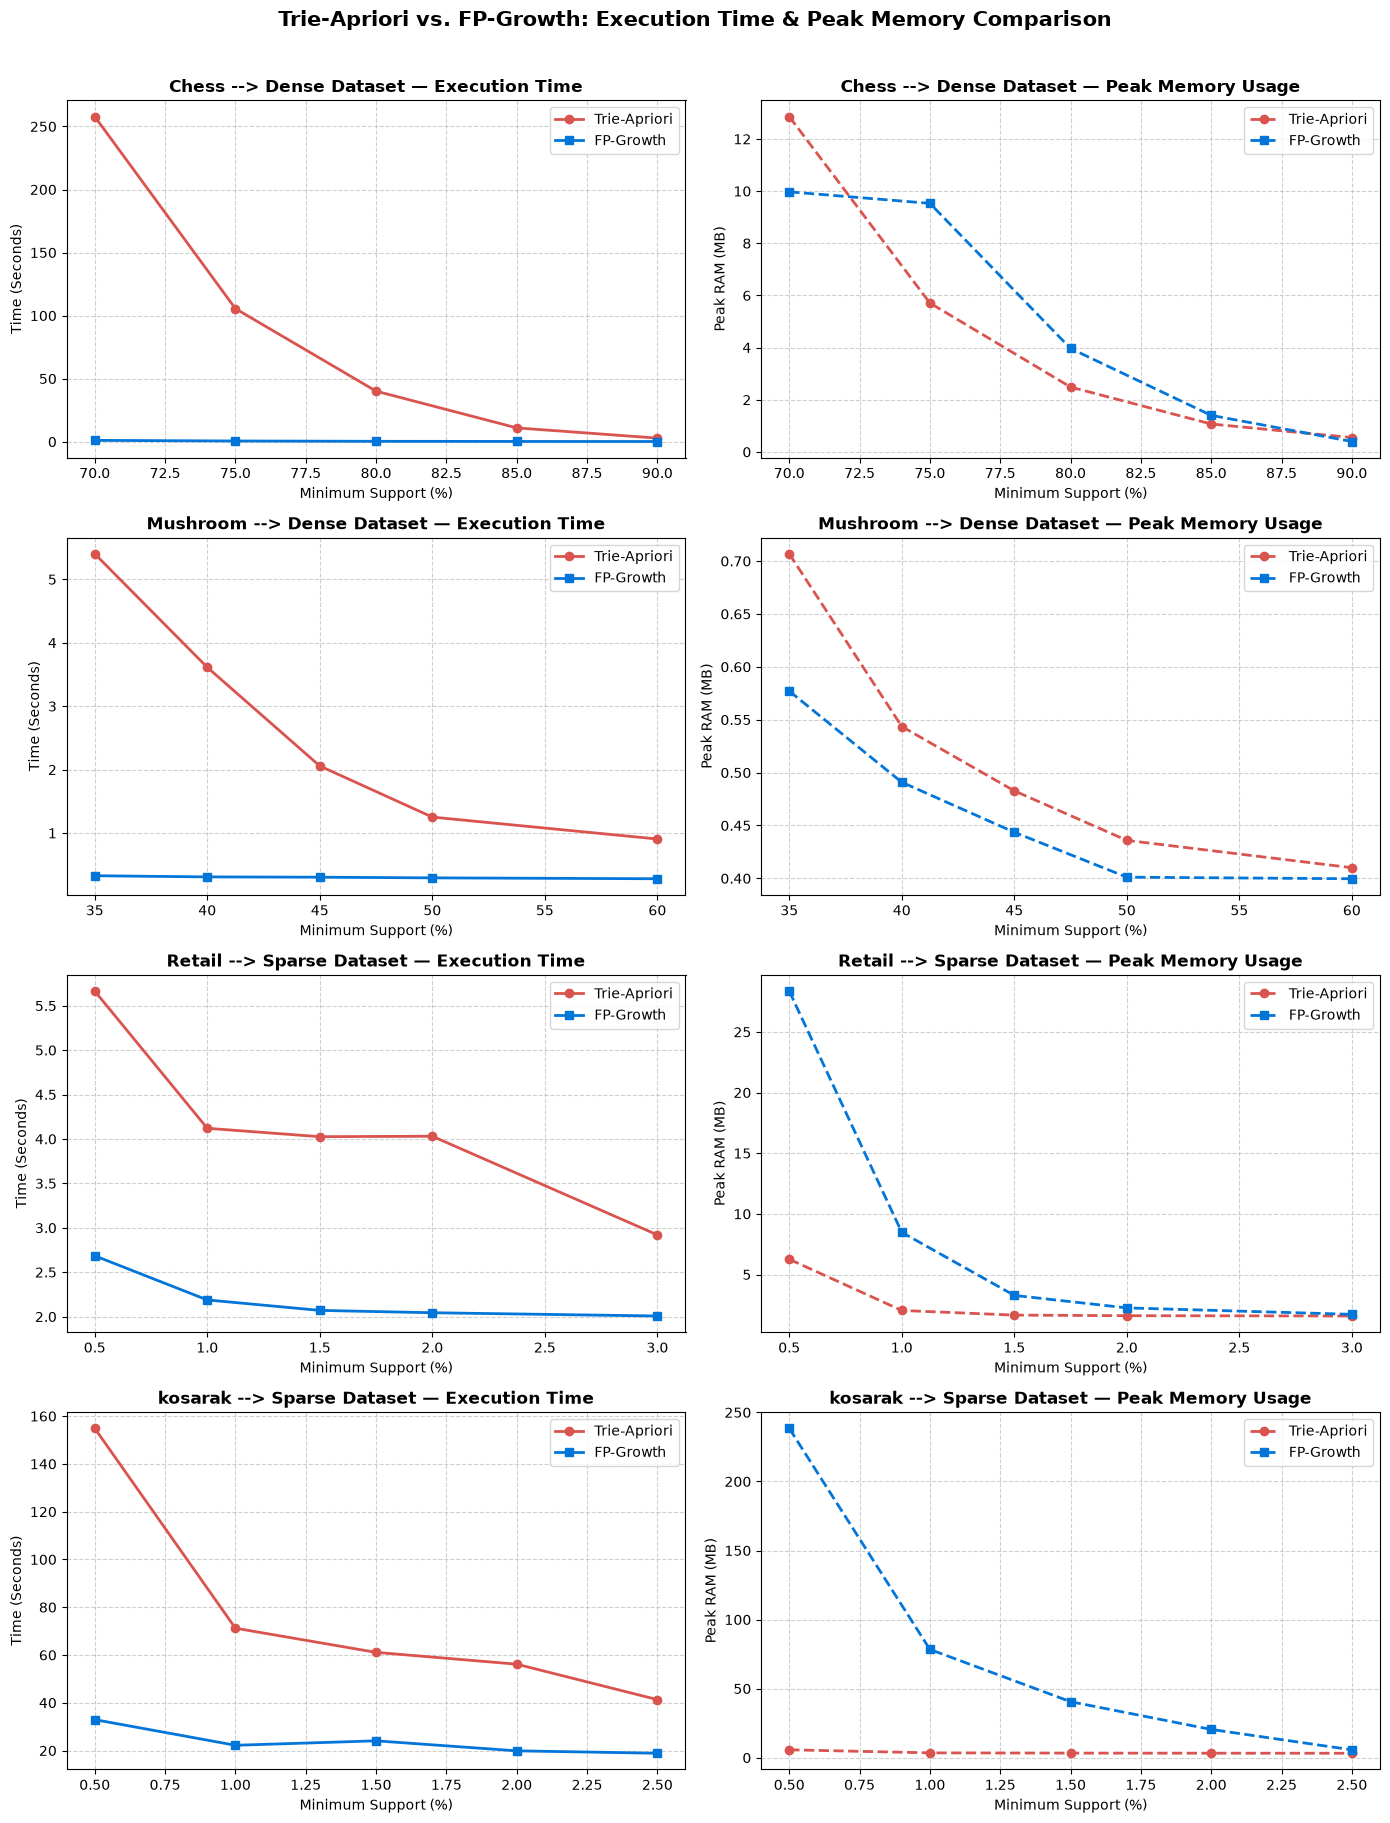

In [ ]:
dense_configs = [
    ("Chess --> Dense Dataset", "datasets/chess.dat.gz", [0.70, 0.75, 0.80, 0.85, 0.90]),
    ("Mushroom --> Dense Dataset", "datasets/mushroom.dat.gz", [0.35, 0.40, 0.45, 0.50, 0.60]),
]

sparse_configs = [
    ("Retail --> Sparse Dataset", "datasets/retail.dat.gz", [0.005, 0.01, 0.015, 0.02, 0.03]),
    ("kosarak --> Sparse Dataset", "datasets/kosarak.dat.gz", [0.005, 0.01, 0.015, 0.02, 0.025]),
]

results_by_dataset = {}
for name, path, thresholds in dense_configs + sparse_configs:
    results_by_dataset[name] = run_comparison_benchmark(name, path, thresholds)

combined_df = pd.concat(results_by_dataset.values(), ignore_index=True)
combined_df.to_csv("apriori_vs_fpgrowth_metrics.csv", index=False)
plot_comparisons(results_by_dataset)